# Scientific Computing 1: Track Finding


In [1]:
import numpy as np
import matplotlib.pyplot as plt
import random

#Fixed seed so the results can be reproduced
np.random.seed(42)
random.seed(42)

import os
os.makedirs('figures',exist_ok=True) #Folder for the figures of the README

## Sample of Space Points Simulation

In [2]:
class detector:
    """
    Detector consisting of a number of detection planes

    Attributes:
        planes: x coordinates of detection planes
        xRange: limits of axis x values. Array of form [minimum x value, maximum x value] 
        yRange: limits of axis y values. Array of form [minimum y value, maximum y value] 
        efficiency: probability that a hit will be detected
        type: detector type. Either 'Continuous' or 'Discrete'
        nDetectionElements: number of detection elements in which a plane is divided for the discrete case
        noise: probability of detecting extra hits
    """
    def __init__(self,nPlanes,planeRange,yRange,efficiency,type,nDetectionElements,noise):
        """
        Initializes a detector object

        Parameters:
            nPlanes: Number of planes
            planeRange: array of the form [initial plane x coordinate, final plane x coordinate]        
            yRange: array of the form [minimum y value, maximum y value]   
            efficiency: probability that a hit will be detected
            type: detector type. Either 'Continuous' or 'Discrete'
            nDetectionElements: number of detection elements in which a plane is divided for the discrete case
            noise: probability of detecting extra hits
        """

        #A message is displayed if the detector type is not correct
        if type!='Continuous' and type!='Discrete':
            print('Type argument must be \'Continuous\' or \'Discrete\' ')
            return
            
        self.planes=np.linspace(planeRange[0],planeRange[1],nPlanes) #Equal distance between planes is assumed   
        self.xRange=[0,self.planes[nPlanes-1]+self.planes[nPlanes-1]-self.planes[nPlanes-2]]
        self.yRange=yRange 
        self.efficiency=efficiency
        self.type=type
        self.nDetectionElements=nDetectionElements
        self.noise=noise

    def plot(self):
        """
        Plots the detector planes
        """
        #Plots planes of detection
        for i in range(len(self.planes)):
            plt.axvline(self.planes[i],color='Turquoise',zorder=1)

        #Axis format
        plt.axis([self.xRange[0],self.xRange[1],self.yRange[0],self.yRange[1]])
        plt.xlabel("x arbitrary coordinate")
        plt.ylabel("y arbitrary coordinate")
        plt.title(self.type+' detector. '+ 'Efficiency of '+str(self.efficiency*100)+'%'\
                 ' Noise of '+str(self.noise*100)+'%');
        
        plt.grid()

In [3]:
class spacePoints:
    """
    Generates a sample of space points in a given detector

    Attributes:
        nParticles: Number of particles
        mRange: limits for determining random m value in linear trajectory y=mx+b. Array of form [minimum m value, maximum m value]
        bRange: limits for determining random b value in linear trajectory y=mx+b. Array of form [minimum b value, maximum b value]
        detector: detector type object
        coordinates: numpy array of space points coordinates of the forms [x,y]      
        mTrue: m values of the true particle trajectories
        bTrue: b values of the true particle trajectories
    """
    
    def __init__(self,nParticles,mRange,bRange,detector):
        """
        Initializes a spacePoints object

        Parameters:
            nParticles: Number of particles
            mRange: array of the form [minimum m value, maximum m value]
            bRange: array of the form [minimum b value, maximum b value] 
            detector: detector type object    
        """
        self.nParticles=nParticles
        self.mRange=mRange
        self.bRange=bRange
        self.detector=detector

        #Depending on the type of detector a different function is used
        if self.detector.type=='Continuous': 
            self.coordinates=self.continuousSample()
            
        if self.detector.type=='Discrete':
            self.coordinates=self.discreteSample()

             
    def continuousSample(self):
        """
        Creates a sample of space points considering continuous detection planes
   
        Returns array of space points coordinates of the form [x,y]
        """
        #Generate a uniform random sample of N values for m and b for the N particle trajectories
        m=np.random.uniform(low=self.mRange[0], high=self.mRange[1], size=self.nParticles)
        b=np.random.uniform(low=self.bRange[0], high=self.bRange[1], size=self.nParticles)
        self.mTrue=m #True trajectories are saved to evaluate the track finding
        self.bTrue=b

        spacePoints=np.empty_like([0,0]) #A spacePoints array is initialized
        
        #Find intersections of each particle trajectory with each of the detection planes
        for i in range(len(self.detector.planes)):
            for j in range(self.nParticles):
                num=random.random() #Generates a random number

                #Record hit according to detector efficiency
                if num<self.detector.efficiency:
                    coordinate=np.array([self.detector.planes[i],m[j]*self.detector.planes[i]+b[j]]) #Evaluate trajectory on detection plane
                    spacePoints=np.vstack([spacePoints, coordinate])

                #Generate extra hit per each real hit according to detector noise
                if num<self.detector.noise:
                    x=self.detector.planes[i]
                    y=random.uniform(self.detector.yRange[0], self.detector.yRange[1])
                    coordinate=np.array([x,y])
                    spacePoints=np.vstack([spacePoints, coordinate])

        spacePoints=np.delete(spacePoints,0,0) #Eliminate initial arbitrary value

        return spacePoints

    def discreteSample(self):
        """
        Creates a sample of space points considering discrete detection planes. The hit is only measured 
        in the center of a detecting element 
        
        Returns array of space points coordinates of the form [x,y]
        """
        #Generate a uniform random sample of N values for m and b for the N particle trajectories
        m=np.random.uniform(low=self.mRange[0], high=self.mRange[1], size=self.nParticles)
        b=np.random.uniform(low=self.bRange[0], high=self.bRange[1], size=self.nParticles)
        self.mTrue=m #True trajectories are saved to evaluate the track finding
        self.bTrue=b

        #Discretization of detection planes
        yElements=np.linspace(self.detector.yRange[0],self.detector.yRange[1],self.detector.nDetectionElements+1) #limits of detection elements

        spacePoints=np.empty_like([0,0])#A spacePoints array is initialized

        #Find the intersections of each particle trajectory with the detection planes
        for i in range(len(self.detector.planes)):
            for j in range(self.nParticles):
                num=random.random() #Generates random number

                #Record hit according to detector efficiency
                if num<self.detector.efficiency:
                    coordinate=np.array([self.detector.planes[i],m[j]*self.detector.planes[i]+b[j]]) #Evaluate trajectory on detection plane

                    #Find in which detection element the y variable is and give a centered value to it
                    for k in range(len(yElements)):
                        if coordinate[1]>yElements[k] and coordinate[1]<yElements[k+1]:
                            coordinate[1]=(yElements[k]+yElements[k+1])/2
                    
                    spacePoints=np.vstack([spacePoints, coordinate])

                #Generate extra hit per each real hit according to detector noise
                if num<self.detector.noise:
                    x=self.detector.planes[i]
                    y=random.uniform(self.detector.yRange[0], self.detector.yRange[1])
                    coordinate=np.array([x,y])

                    #Find in which detection element the y variable is and give a centered value to it
                    for k in range(len(yElements)):
                        if coordinate[1]>yElements[k] and coordinate[1]<yElements[k+1]:
                            coordinate[1]=(yElements[k]+yElements[k+1])/2
                    
                    spacePoints=np.vstack([spacePoints, coordinate])

        spacePoints=np.delete(spacePoints,0,0) #Eliminate initial arbitrary value
   
        return spacePoints

    def plot(self):
        """ 
        Creates a plot for the space points
        """
        self.detector.plot() #Plot detector
        
        #Plot scatter of spacePoints
        plt.scatter(self.coordinates[:,0],self.coordinates[:,1],color='k',s=1,zorder=2)

        #Axis format
        plt.title(self.detector.type+' '+str(self.nParticles)+' particles Space Points. Efficiency of '+str(self.detector.efficiency*100)+'%'\
                 ' Noise of '+str(self.detector.noise*100)+'%');

## Track Finding Algorithm

In [4]:
class trackFinder:
    """
    Finds particle trajectories from a given set of space points

    Attributes:
        detector: detector type object
        spacePoints: spcePoints type object  
        dm: discretization of m domain
        nBins: number of divisions of the mb space for voting system
        threshold: threshold for voting system
        hLines: numpy array of Hough lines
        intersections: numpy array of intersection coordinates of the forms [x,y]
        dx: established discretization of x domain
        nParticlesDetected: number of detected particles from track finding algorithm
        method: voting system. '1D' uses separate histograms of m and b, '2D' uses a histogram of the mb space
    """

    def __init__(self,detector,spacePoints,nBins,threshold,method='1D'):
        """
        Initializes a trackFinder object

        Parameters:
            detector: detector type object    
            spacePoints: spcePoints type object
            nBins: number of divisions of the mb space for voting system
            threshold: threshold for voting system
            method: voting system, either '1D' or '2D'
        """
        self.detector=detector
        self.method=method
        self.spacePoints=spacePoints          
        self.dm=0.0001 #Established discretization of m domain
        self.hLines=self.HoughTransform() #Perform Hough transform
        self.intersections=self.realIntersections(nBins,threshold) #Decide valid Hough points with voting system
        self.dx=0.0001 #Established discretization of x domain

        #Determine number of particles from found trajectories. -99 represents that no trajectory was found
        if -99 in self.intersections:
            self.nParticlesDetected=0
        else:       
            self.nParticlesDetected=len(self.intersections)

               
    def intersect(self,A,B,C,D,xRange,yRange):
        """
        Finds intersection of line segments defined by AB and CD using a determinant method

        Parameters:
            A: defining point of line segmente. Array with form [x,y]
            B: defining point of line segmente. Array with form [x,y]
            C: defining point of line segmente. Array with form [x,y]
            D: defining point of line segmente. Array with form [x,y]
            xRange: limits of detector planes x values. Array of form [minimum x value, maximum x value] 
            yRange: limits of detector planes y values. Array of form [minimum y value, maximum y value]
           
        Returns the intersection point as [x,y]. Returns [-99,99] if no intersection is found.
        """
        a1=B[1]-A[1]
        b1=A[0]-B[0]
        c1=a1*A[0]+b1*A[1]

        a2=D[1]-C[1]
        b2=C[0]-D[0]
        c2=a2*C[0]+b2*C[1]

        determinant=a1*b2-a2*b1

        #If the determinant is 0 then no intersection is found along the domain
        if determinant==0:
            intersect=[-99,-99]

        else:
            intersect=np.array([(b2*c1 - b1*c2)/determinant,(a1*c2 - a2*c1)/determinant])

        #If the intersection is found outside the domain it is not counted
        if intersect[0]<xRange[0] or intersect[0]>xRange[1] or intersect[1]<yRange[0] or intersect[1]>yRange[1]:
            intersect=[-99,-99]
            
        return intersect
    
    def HoughTransform(self):
        """
        Performs Hough Transform for a given set of space points

        Parameters:
            mPoint: number of m discretization
            
        Returns numpy array of Hough lines
        """

        N=len(self.spacePoints.coordinates) #Number of points equal to number of Hough lines
        nM=int((self.spacePoints.mRange[1]-self.spacePoints.mRange[0])/self.dm)+1 #Number of linspace points
        m=np.linspace(self.spacePoints.mRange[0],self.spacePoints.mRange[1],nM) #Domain for m values
        hLines=np.zeros([N,len(m)]) #Array for N b=y-mx lines

        #Evaluate each Hough line
        for i in range(N):
            hLines[i]=self.spacePoints.coordinates[i,1]-m*self.spacePoints.coordinates[i,0]
    
        return hLines

    def realIntersections(self,nBins,threshold):
        """
        Finds and validates intersections in Hough transform with voting system.

        Parameters:
            nBins: number of divisions of the mb space
            threshold: threshold for voting system

        Returns numpy array of intersections of the form [m,b]. Returns a -99 2D array if no intersection is found.
        """
        N=len(self.hLines) #Number of Hough lines
        nM=int((self.spacePoints.mRange[1]-self.spacePoints.mRange[0])/self.dm)+1 #Number of linspace points
        m=np.linspace(self.spacePoints.mRange[0],self.spacePoints.mRange[1],nM) #Domain for m values

        intersections=np.empty_like([0,0]) #Initialize intersections array

        #Look for intersection of every line with every other line
        for i in range(N):
            for j in range(N):
                A=np.array([m[0],self.hLines[i,0]])
                B=np.array([m[len(m)-1],self.hLines[i,len(m)-1]])
                C=np.array([m[0],self.hLines[j,0]])
                D=np.array([m[len(m)-1],self.hLines[j,len(m)-1]])

                inter=self.intersect(A,B,C,D,self.spacePoints.mRange,self.spacePoints.bRange)

                if inter[0]!=-99: #If an intersection is found then it is added in the array
                    intersections=np.vstack([intersections, np.array(inter)])

        intersections=np.delete(intersections,0,0) #Eliminate initial arbitrary value

        #If no intersection was found then an array of -99 is returned
        if intersections.ndim==1:
            self.threshold=threshold
            return np.array([[-99,-99],[-99,-99]])

        #Voting system with a 2D histogram of the mb space
        if self.method=='2D':
            self.threshold=threshold
            return self.vote2D(intersections,nBins,threshold)
        
        #Bins count of m and b values. The bins cover the whole m and b ranges
        countsM,binsM=np.histogram(intersections[:,0],bins=nBins,range=self.spacePoints.mRange)
        countsB,binsB=np.histogram(intersections[:,1],bins=nBins,range=self.spacePoints.bRange)

        #Voting system for bins with higher count than the threshold
        acceptedBinsM=np.empty_like([0,0]) 
        acceptedBinsB=np.empty_like([0,0]) 

        for i in range(len(countsM)):
            #If the count is higher than threshold, the corresponding bin is added in an array
            if countsM[i]>threshold:
                acceptedBinsM=np.vstack([acceptedBinsM,np.array([binsM[i],binsM[i+1]])])
            if countsB[i]>threshold:
                acceptedBinsB=np.vstack([acceptedBinsB,np.array([binsB[i],binsB[i+1]])])
        
        #Eliminate initial arbitrary value
        acceptedBinsM=np.delete(acceptedBinsM,0,0) 
        acceptedBinsB=np.delete(acceptedBinsB,0,0)

        #If no bin was accepted then an array of -99 is returned (the array is left with a single value)
        if acceptedBinsM.ndim==1 or acceptedBinsB.ndim==1:
            self.threshold=threshold
            return np.array([[-99,-99],[-99,-99]])
    
        #Filtrate intersections to only consider those within the accepted bins
        trueIntersections=np.empty_like([0,0])

        #Each intersection is revised if lies within a given bin
        for i in range(len(acceptedBinsB)):        
            for j in range(len(acceptedBinsM)):
                #As there will be multiple intersections with slight variation within a same bin, an average will be taken of these
                sumM=0
                sumB=0
                c=0 #Counter for the average calculation
                for h in range(len(intersections)):
                    if intersections[h,0]>=acceptedBinsM[j,0] and intersections[h,0]<=acceptedBinsM[j,1]\
                        and intersections[h,1]>=acceptedBinsB[i,0] and intersections[h,1]<=acceptedBinsB[i,1]:
                        sumM=sumM+intersections[h,0]
                        sumB=sumB+intersections[h,1]
                        c=c+1
                    
                #If c is different than 0 at least one intersection was found in the given bin
                if c!=0:
                    trueIntersections=np.vstack([trueIntersections, np.array([sumM/c, sumB/c])])
                    
        trueIntersections=np.delete(trueIntersections,0,0) #Eliminate initial arbitrary value    
        self.threshold=threshold #Set value of object attribute

        #If no intersection was inside the accepted bins then an array of -99 is returned
        if trueIntersections.ndim==1:
            return np.array([[-99,-99],[-99,-99]])
        
        return trueIntersections

    def vote2D(self,intersections,nBins,threshold):
        """
        Voting system with a 2D histogram of the mb space. Each bin of the histogram is a combination of m and b, 
        so only the combinations where the intersections really accumulate are accepted.

        Parameters:
            intersections: numpy array of intersections of the form [m,b]
            nBins: number of divisions of m and of b
            threshold: threshold for voting system

        Returns numpy array of intersections of the form [m,b]. Returns a -99 2D array if no intersection is found.
        """
        counts,binsM,binsB=np.histogram2d(intersections[:,0],intersections[:,1],bins=nBins,\
                                          range=[self.spacePoints.mRange,self.spacePoints.bRange])

        #Bin of each intersection
        iM=np.clip(np.digitize(intersections[:,0],binsM)-1,0,nBins-1)
        iB=np.clip(np.digitize(intersections[:,1],binsB)-1,0,nBins-1)

        #The intersections of one trajectory can fall in neighbouring bins, so each bin is summed with its 8 neighbours
        padded=np.pad(counts,1)
        votes=np.zeros_like(counts)
        for di in [-1,0,1]:
            for dj in [-1,0,1]:
                votes=votes+padded[1+di:1+di+nBins,1+dj:1+dj+nBins]

        #Only the bins with more votes than all their neighbours are kept, so one trajectory is not counted twice
        paddedVotes=np.pad(votes,1,constant_values=-1)
        isPeak=np.ones_like(votes,dtype=bool)
        for di in [-1,0,1]:
            for dj in [-1,0,1]:
                if di==0 and dj==0:
                    continue
                neighbour=paddedVotes[1+di:1+di+nBins,1+dj:1+dj+nBins]
                #For equal votes only one of the two bins is kept
                if (di,dj)<(0,0):
                    isPeak=isPeak&(votes>neighbour)
                else:
                    isPeak=isPeak&(votes>=neighbour)

        trueIntersections=[]

        #Each accepted bin gives one trajectory, the mean of the intersections in the bin and its neighbours
        for i,j in zip(*np.where((votes>threshold)&isPeak)):
            inBin=(np.abs(iM-i)<=1)&(np.abs(iB-j)<=1)
            trueIntersections.append([np.mean(intersections[inBin,0]),np.mean(intersections[inBin,1])])

        #If no bin was accepted then an array of -99 is returned
        if len(trueIntersections)==0:
            return np.array([[-99,-99],[-99,-99]])

        return np.array(trueIntersections)

    def trajectories(self):
        """
        Calculates the particle trajectories

        Returns an array of y=mx+b lines. Returns a -99 2D array if no trajectory is found.
        """
        #If no intersection was found, then there are no trajectories
        if self.intersections[0,0]==-99:
            return np.array([[-99,-99],[-99,-99]])

        nX=int((self.detector.xRange[1]-self.detector.xRange[0])/self.dx)+1 #Number of linspace points        
        x=np.linspace(self.detector.xRange[0], self.detector.xRange[1], nX) #Domain for x 
        N=len(self.intersections) #Number of detected particles
        trajectories=np.zeros([N,len(x)]) 

        #Calculating trajectories with y=mx+b
        for i in range(N):
            trajectories[i]=self.intersections[i,0]*x+self.intersections[i,1]

        return trajectories

    def evaluate(self,mTol=0.05,bTol=0.1):
        """
        Compares the detected trajectories with the true trajectories of the sample. A detected trajectory
        is correct if its m and b values are within mTol and bTol of a true trajectory that was not matched before.

        Parameters:
            mTol: tolerance for m
            bTol: tolerance for b

        Returns number of correct trajectories, number of fake trajectories, efficiency (correct/true) and 
        fake rate (fake/detected)
        """
        nTrue=len(self.spacePoints.mTrue)

        #If no trajectory was found there are no correct or fake trajectories
        if self.nParticlesDetected==0 or self.intersections.ndim!=2:
            return 0,0,0,0

        matched=np.zeros(nTrue,dtype=bool) #True trajectories that were already matched
        nCorrect=0

        for i in range(len(self.intersections)):
            dm=np.abs(self.spacePoints.mTrue-self.intersections[i,0])
            db=np.abs(self.spacePoints.bTrue-self.intersections[i,1])
            candidates=np.where((dm<mTol)&(db<bTol)&(~matched))[0]

            #The closest true trajectory is taken as the match
            if len(candidates)>0:
                k=candidates[np.argmin(dm[candidates]/mTol+db[candidates]/bTol)]
                matched[k]=True
                nCorrect=nCorrect+1

        nFake=self.nParticlesDetected-nCorrect

        return nCorrect,nFake,nCorrect/nTrue,nFake/self.nParticlesDetected

    def plotHough(self,fileName=None):
        """
        Creates a plot of the Hough lines and detected intersections

        Parameters:
            fileName: if given, the figure is saved with this name
        """
        N=len(self.hLines) #Number of Hough lines
        nM=int((self.spacePoints.mRange[1]-self.spacePoints.mRange[0])/self.dm)+1 #Number of linspace points
        m=np.linspace(self.spacePoints.mRange[0],self.spacePoints.mRange[1],nM) #Domain for m values

        #Plot Hough lines
        for i in range (len(self.hLines)):
            plt.plot(m,self.hLines[i],color='k',linewidth=0.7)
        
        plt.scatter(self.intersections[:,0],self.intersections[:,1],facecolors='none',edgecolors='r',zorder=2)           
        plt.title(str(self.nParticlesDetected)+' Intersections, Threshold:'+str(self.threshold))

        #Axis format
        plt.axis([self.spacePoints.mRange[0],self.spacePoints.mRange[1],self.spacePoints.bRange[0],self.spacePoints.bRange[1]])
        plt.xlabel("m arbitrary coordinate")
        plt.ylabel("b arbitrary coordinate")

        plt.grid()
        if fileName!=None:
            plt.savefig(fileName,dpi=200,bbox_inches='tight')
        plt.show()

    def plotTrajectories(self,fileName=None):
        """
        Creates a plot of the space points and calculated trajectories

        Parameters:
            fileName: if given, the figure is saved with this name
        """
        #Plot space points
        self.spacePoints.plot()

        #If intersection array contains -99, then there are no trajectories
        if self.intersections[0,0]!=-99:
            nX=int((self.detector.xRange[1]-self.detector.xRange[0])/self.dx)+1 #Number of linspace points        
            x=np.linspace(self.detector.xRange[0], self.detector.xRange[1], nX) #Domain for x 
            N=len(self.intersections)
        
            #Plot the trajectories
            trajectories=self.trajectories()
            for i in range(N):
                plt.plot(x,trajectories[i],color='k',linewidth=0.7)

        #Axis format
        plt.axis([self.detector.xRange[0],self.detector.xRange[1],self.detector.yRange[0],self.detector.yRange[1]])
        plt.xlabel("x arbitrary coordinate")
        plt.ylabel("y arbitrary coordinate")
        plt.title('Particle trajectories: '+str(self.nParticlesDetected))
        if fileName!=None:
            plt.savefig(fileName,dpi=200,bbox_inches='tight')
        plt.show()

## Performance Evaluation

### Single trials

Ideal scenario: Continuous detecting elements, no noise, 100% efficiency

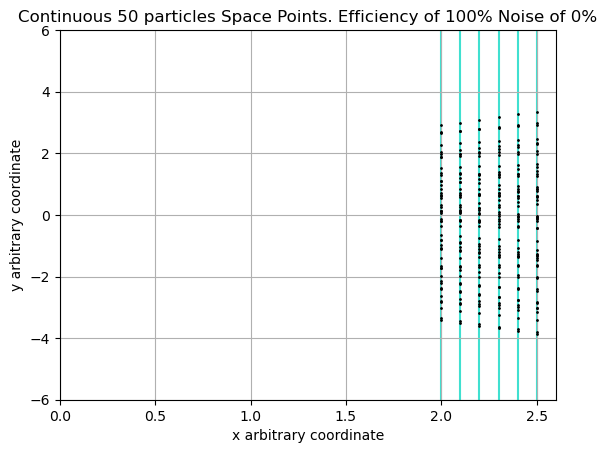

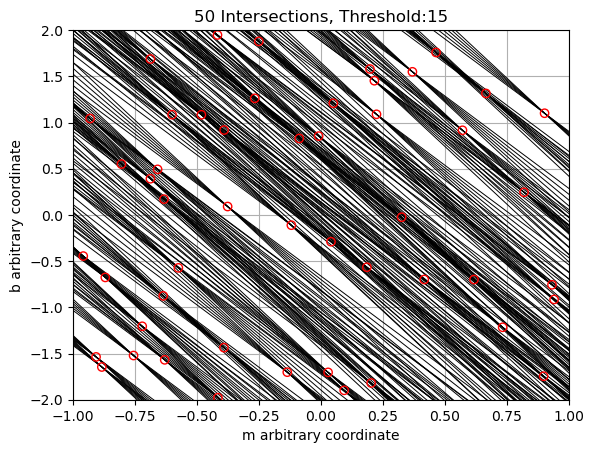

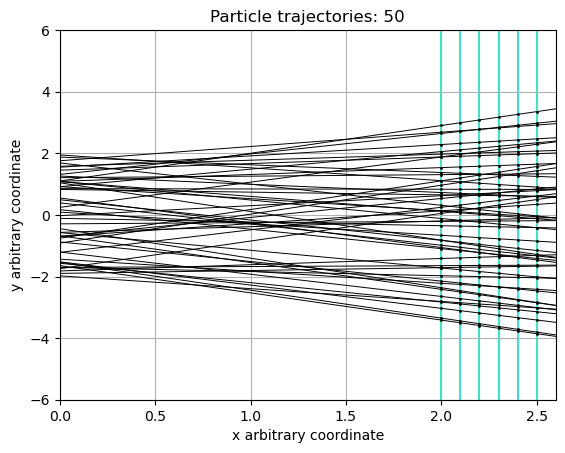

Detected: 50  Correct: 50  Fake: 0
Efficiency: 1.0  Fake rate: 0.0


In [5]:
#Detector parameters
nPlanes=6
planeRange=[2,2.5]
yRange=[-6,6]
efficiency=1
nDetectionE=5000
type='Continuous' #'Discrete' or 'Continuous'
noise=0

detector1=detector(nPlanes,planeRange,yRange,efficiency,type,nDetectionE,noise)

#Space points parameters
nParticles=50
mRange=np.array([-1,1])
bRange=np.array([-2,2])

sample1=spacePoints(nParticles,mRange,bRange,detector1)

sample1.plot()
plt.show()

#Track finding parameters
nBins=5000
threshold=15
trackFinder1=trackFinder(detector1,sample1,nBins,threshold)
trackFinder1.plotHough('figures/hough_ideal.png')
trackFinder1.plotTrajectories('figures/trajectories_ideal.png')

nCorrect,nFake,ef,fakeRate=trackFinder1.evaluate()
print('Detected:',trackFinder1.nParticlesDetected,' Correct:',nCorrect,' Fake:',nFake)
print('Efficiency:',ef,' Fake rate:',fakeRate)

Real scenario: Discrete detecting elements, 1% noise, 90% efficiency

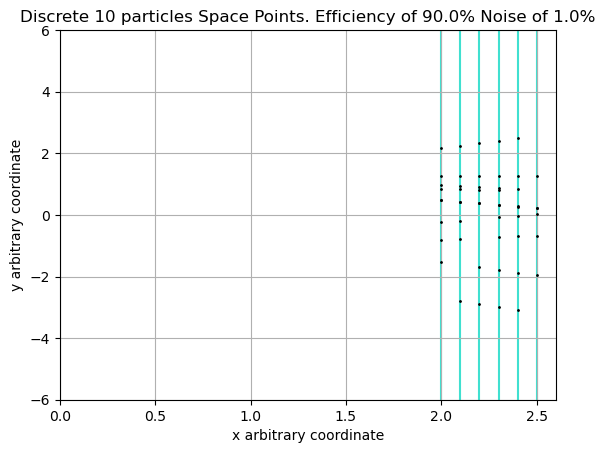

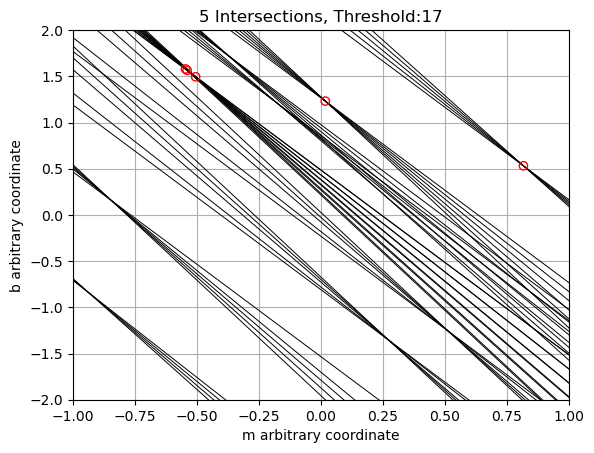

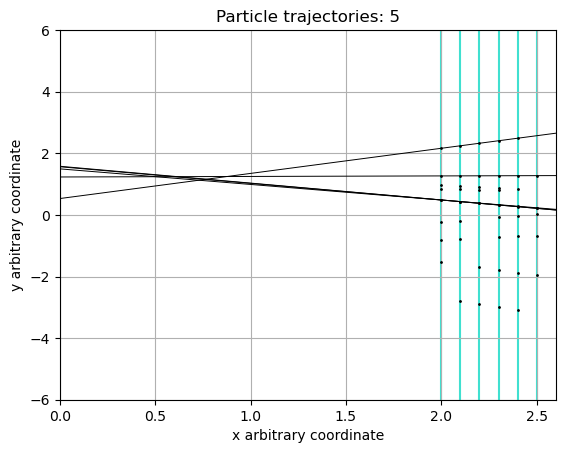

Detected: 5  Correct: 4  Fake: 1
Efficiency: 0.4  Fake rate: 0.2


In [6]:
#Detector parameters
nPlanes=6
planeRange=[2,2.5]
yRange=[-6,6]
efficiency=0.9
nDetectionE=5000
type='Discrete' #'Discrete' or 'Continuous'
noise=0.01

detector2=detector(nPlanes,planeRange,yRange,efficiency,type,nDetectionE,noise)

#Space points parameters
nParticles=10
mRange=np.array([-1,1])
bRange=np.array([-2,2])

sample2=spacePoints(nParticles,mRange,bRange,detector2)

sample2.plot()
plt.show()

#Track finding parameters
nBins=100
threshold=17
trackFinder2=trackFinder(detector2,sample2,nBins,threshold)
trackFinder2.plotHough('figures/hough_real.png')
trackFinder2.plotTrajectories('figures/trajectories_real.png')

nCorrect,nFake,ef,fakeRate=trackFinder2.evaluate()
print('Detected:',trackFinder2.nParticlesDetected,' Correct:',nCorrect,' Fake:',nFake)
print('Efficiency:',ef,' Fake rate:',fakeRate)

### Real and fake trajectories
The detected trajectories are compared with the true trajectories of the sample for 10 and 30 particles in the real scenario. The proportion of detected to real particles used in the statistics below counts fake trajectories as if they were real ones.

In [7]:
#Detector parameters
nPlanes=6
planeRange=[2,2.5]
yRange=[-6,6]
efficiency=0.9
nDetectionE=5000
type='Discrete' #'Discrete' or 'Continuous'
noise=0.01

detector3=detector(nPlanes,planeRange,yRange,efficiency,type,nDetectionE,noise)

#Space points parameters
mRange=np.array([-1,1])
bRange=np.array([-2,2])

#Track finding parameters
nBins=100
threshold=15

N=5 #Number of trials

for nParticles in [10,30]:
    for i in range(N):
        sample3=spacePoints(nParticles,mRange,bRange,detector3)
        trackFinder3=trackFinder(detector3,sample3,nBins,threshold)
        nCorrect,nFake,ef,fakeRate=trackFinder3.evaluate()
        print(nParticles,'particles. Detected:',trackFinder3.nParticlesDetected,' Correct:',nCorrect,' Fake:',nFake)

10 particles. Detected: 11  Correct: 8  Fake: 3
10 particles. Detected: 11  Correct: 9  Fake: 2
10 particles. Detected: 12  Correct: 10  Fake: 2
10 particles. Detected: 12  Correct: 6  Fake: 6
10 particles. Detected: 12  Correct: 9  Fake: 3
30 particles. Detected: 170  Correct: 30  Fake: 140
30 particles. Detected: 189  Correct: 29  Fake: 160
30 particles. Detected: 211  Correct: 30  Fake: 181
30 particles. Detected: 155  Correct: 30  Fake: 125
30 particles. Detected: 103  Correct: 30  Fake: 73


### 1D and 2D voting system
With separate histograms for m and b, every accepted m bin is combined with every accepted b bin, so with k real trajectories up to k² combinations are accepted and most of them are fake. With a 2D histogram only the combinations where the intersections accumulate are accepted. Both methods are compared over 20 trials in the real scenario.

In [8]:
#Detector parameters
nPlanes=6
planeRange=[2,2.5]
yRange=[-6,6]
efficiency=0.9
nDetectionE=5000
type='Discrete' #'Discrete' or 'Continuous'
noise=0.01

detector4=detector(nPlanes,planeRange,yRange,efficiency,type,nDetectionE,noise)

#Space points parameters
mRange=np.array([-1,1])
bRange=np.array([-2,2])

#Track finding parameters
nBins=100
threshold=15

N=20 #Number of trials

for nParticles in [10,30]:
    for method in ['1D','2D']:
        results=np.zeros([N,2])
        for i in range(N):
            sample4=spacePoints(nParticles,mRange,bRange,detector4)
            trackFinder4=trackFinder(detector4,sample4,nBins,threshold,method)
            nCorrect,nFake,ef,fakeRate=trackFinder4.evaluate()
            results[i]=[ef,nFake/nParticles]
        print(nParticles,'particles,',method,'voting. Efficiency:',round(np.mean(results[:,0]),3),\
              ' Fake trajectories per real one:',round(np.mean(results[:,1]),3))

10 particles, 1D voting. Efficiency: 0.73  Fake trajectories per real one: 0.15
10 particles, 2D voting. Efficiency: 0.87  Fake trajectories per real one: 0.01
30 particles, 1D voting. Efficiency: 0.982  Fake trajectories per real one: 6.03
30 particles, 2D voting. Efficiency: 0.878  Fake trajectories per real one: 0.27


### Statistics

In [9]:
class stats:
    """
    Functions to run statistical analysis of the track finding algorithm
    """
    def parameterVariance(parameter,values,params,N):
        """
        Statistical algorithm for doing multiple trials for different values of one parameter

        Parameters:
            parameter: name of the varying parameter, one of the keys of params
            values: array of values of the varying parameter
            params: dictionary with all the detector, space points and track finding parameters
            N: number of trials per value

        Returns two numpy arrays with the efficiency (correct/true) and the fake trajectories per true trajectory
        of each trial
        """
        efficiencies=np.zeros([len(values),N])
        fakes=np.zeros([len(values),N])

        #N trials for each value of the parameter
        for j in range(len(values)):
            p=params.copy()
            p[parameter]=values[j]

            detector1=detector(p['nPlanes'],p['planeRange'],p['yRange'],p['efficiency'],p['type'],int(p['nDetectionE']),p['noise'])
            for i in range(N):
                sample1=spacePoints(int(p['nParticles']),p['mRange'],p['bRange'],detector1)
                trackFinder1=trackFinder(detector1,sample1,int(p['nBins']),int(p['threshold']),p['method'])
                nCorrect,nFake,ef,fakeRate=trackFinder1.evaluate()
                efficiencies[j,i]=ef #Proportion of true trajectories found
                fakes[j,i]=nFake/int(p['nParticles']) #Fake trajectories per true trajectory
        return efficiencies,fakes

    def compareMethods(parameter,values,params,N,variable,fileName):
        """
        Runs the statistical analysis with the 1D and 2D voting systems and plots the mean and standard deviation 
        of the efficiency and of the fake trajectories

        Parameters:
            parameter: name of the varying parameter, one of the keys of params
            values: array of values of the varying parameter
            params: dictionary with all the detector, space points and track finding parameters
            N: number of trials per value
            variable: name of varying parameter for the plot
            fileName: name of the saved figure

        Returns a dictionary with the efficiencies and fakes of each method
        """
        results={}
        fig,axes=plt.subplots(1,2,figsize=(11,4))

        for method,color in [('1D','tab:blue'),('2D','tab:orange')]:
            p=params.copy()
            p['method']=method
            efficiencies,fakes=stats.parameterVariance(parameter,values,p,N)
            results[method]=[efficiencies,fakes]

            axes[0].errorbar(values,np.mean(efficiencies,axis=1),yerr=np.std(efficiencies,axis=1),fmt='o',\
                             color=color,capsize=2,markersize=4,label=method+' voting')
            axes[1].errorbar(values,np.mean(fakes,axis=1),yerr=np.std(fakes,axis=1),fmt='o',\
                             color=color,capsize=2,markersize=4,label=method+' voting')

        axes[0].set_ylabel('Efficiency (true trajectories found)')
        axes[1].set_ylabel('Fake trajectories per true trajectory')
        for ax in axes:
            ax.set_xlabel(variable)
            ax.grid()
            ax.legend()
        fig.suptitle(variable+' dependance (mean and standard deviation of '+str(N)+' trials)')
        plt.tight_layout()
        plt.savefig(fileName,dpi=200,bbox_inches='tight')
        plt.show()

        return results


Every analysis uses the real scenario parameters and only changes one of them. Each point is the mean of 100 trials, error bars are the standard deviation. The whole section takes around 2 hours, most of it in the number of particles analysis, because the 1D voting system becomes slow with many fake trajectories.

In [10]:
#Real scenario parameters
params={
    #Detector parameters
    'nPlanes':6,
    'planeRange':[2,2.5],
    'yRange':[-6,6],
    'efficiency':0.9,
    'nDetectionE':5000,
    'type':'Discrete', #'Discrete' or 'Continuous'
    'noise':0.01,
    #Space points parameters
    'nParticles':10,
    'mRange':np.array([-1,1]),
    'bRange':np.array([-2,2]),
    #Track finding parameters
    'nBins':100,
    'threshold':15,
    'method':'1D'
}

N=100 #Number of trials for statistical analysis

#### Number of particles analysis

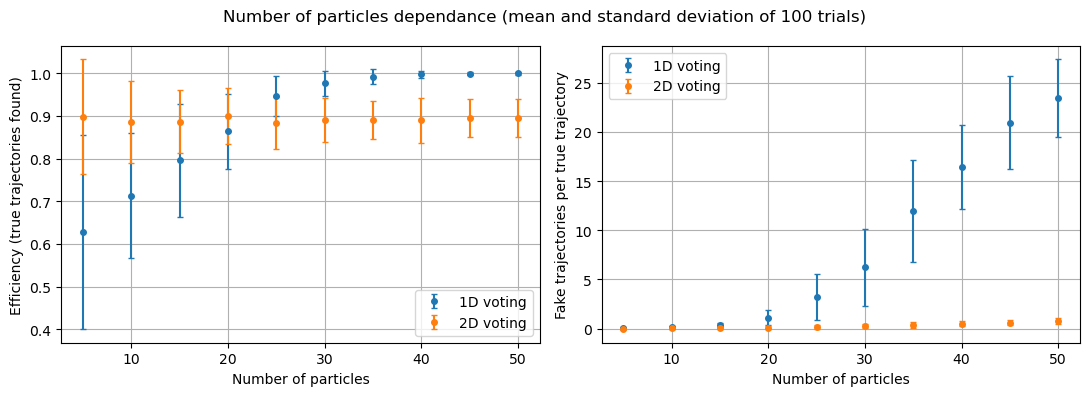

In [11]:
rangeZ=np.array([5,50])
dz=5
values=np.linspace(rangeZ[0],rangeZ[1],int((rangeZ[1]-rangeZ[0])/dz)+1) #Number of particles to try
resultsnParticles=stats.compareMethods('nParticles',values,params,N,'Number of particles','figures/particles.png')

#### Threshold analysis

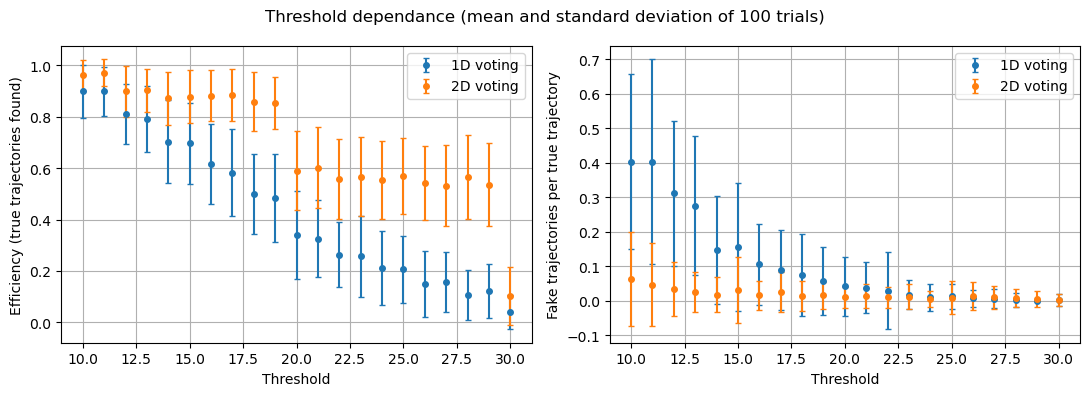

In [12]:
rangeZ=np.array([10,30])
dz=1
values=np.linspace(rangeZ[0],rangeZ[1],int((rangeZ[1]-rangeZ[0])/dz)+1) #Thresholds to try
resultsthreshold=stats.compareMethods('threshold',values,params,N,'Threshold','figures/threshold.png')

#### Number of Bins analysis

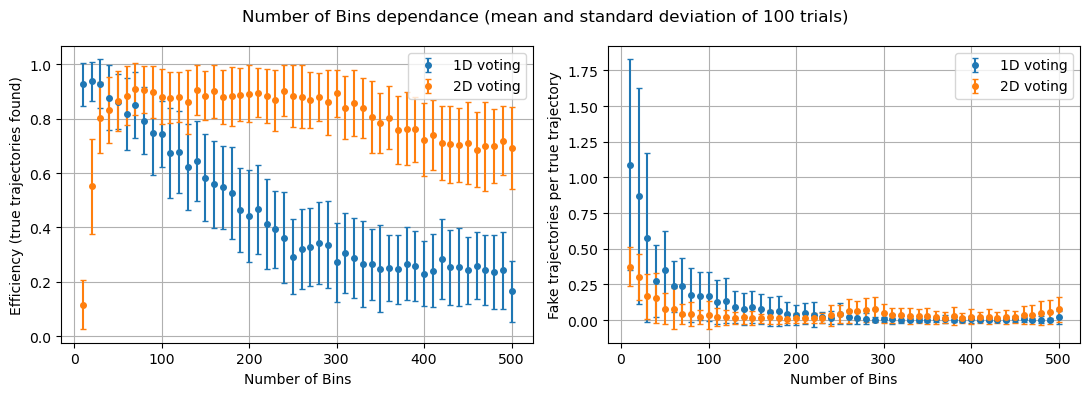

In [13]:
rangeZ=np.array([10,500])
dz=10
values=np.linspace(rangeZ[0],rangeZ[1],int((rangeZ[1]-rangeZ[0])/dz)+1) #Number of bins to try
resultsnBins=stats.compareMethods('nBins',values,params,N,'Number of Bins','figures/bins.png')

#### Detection Elements analysis

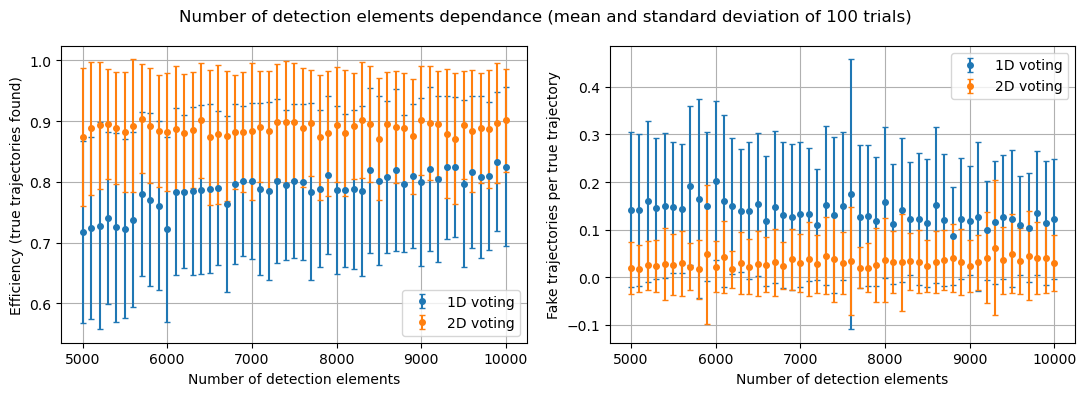

In [14]:
rangeZ=np.array([5000,10000])
dz=100
values=np.linspace(rangeZ[0],rangeZ[1],int((rangeZ[1]-rangeZ[0])/dz)+1) #Number of detection elements to try
resultsnDetectionE=stats.compareMethods('nDetectionE',values,params,N,'Number of detection elements','figures/detection_elements.png')

#### Efficiency analysis

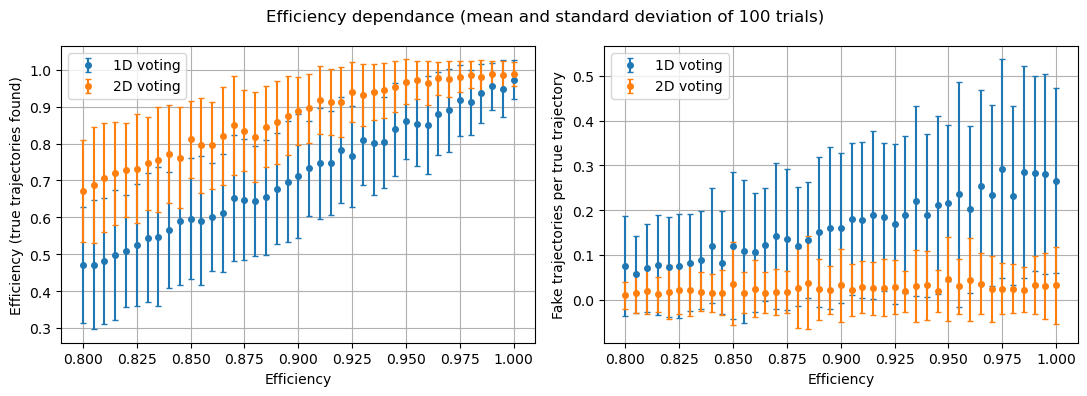

In [15]:
rangeZ=np.array([0.8,1])
dz=0.005
values=np.linspace(rangeZ[0],rangeZ[1],int(round((rangeZ[1]-rangeZ[0])/dz))+1) #Efficiencies to try
resultsefficiency=stats.compareMethods('efficiency',values,params,N,'Efficiency','figures/efficiency.png')

#### Noise analysis

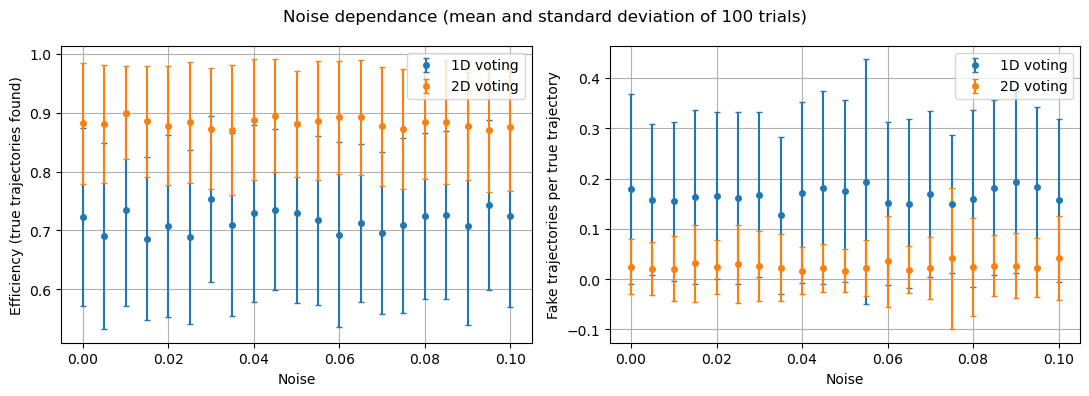

In [16]:
rangeZ=np.array([0,0.1])
dz=0.005
values=np.linspace(rangeZ[0],rangeZ[1],int(round((rangeZ[1]-rangeZ[0])/dz))+1) #Noise values to try
resultsnoise=stats.compareMethods('noise',values,params,N,'Noise','figures/noise.png')